In [1]:
import math
import os

In [2]:
# Training loop and evaluation (train.py), JSON helpers (util.py).
from train import device, evaluate, fit
from util import load_json, save_json

In [3]:
from pathlib import Path

import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset

pd.set_option("display.max_colwidth", 200)

## 1. Data loading

In [4]:
import kagglehub

# Download latest version
data_cache_path = kagglehub.competition_download(
    "jigsaw-toxic-comment-classification-challenge"
)

print("Path to competition files:", data_cache_path)

Path to competition files: /home/pawlowiczf/.cache/kagglehub/competitions/jigsaw-toxic-comment-classification-challenge


In [5]:
path = Path(data_cache_path)

In [6]:
train = pd.read_csv(path / "train.csv.zip")
test = pd.read_csv(path / "test.csv.zip")
test_labels = pd.read_csv(path / "test_labels.csv.zip")

In [7]:
print(train.shape, test.shape, test_labels.shape)

(159571, 8) (153164, 2) (153164, 7)


In [8]:
test = test.merge(test_labels, on="id", how="inner", validate="one_to_one")
test = test[test["toxic"] != -1].reset_index(drop=True)

In [9]:
train["comment_text"] = (
    train["comment_text"].str.replace(r"\s+", " ", regex=True).str.strip()
)

test["comment_text"] = (
    test["comment_text"].str.replace(r"\s+", " ", regex=True).str.strip()
)

In [10]:
train.head()

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,"Explanation Why the edits made under my username Hardcore Metallica Fan were reverted? They weren't vandalisms, just closure on some GAs after I voted at New York Dolls FAC. And please don't remov...",0,0,0,0,0,0
1,000103f0d9cfb60f,"D'aww! He matches this background colour I'm seemingly stuck with. Thanks. (talk) 21:51, January 11, 2016 (UTC)",0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It's just that this guy is constantly removing relevant information and talking to me through edits instead of my talk page. He seems to care more about...",0,0,0,0,0,0
3,0001b41b1c6bb37e,""" More I can't make any real suggestions on improvement - I wondered if the section statistics should be later on, or a subsection of """"types of accidents"""" -I think the references may need tidyin...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember what page that's on?",0,0,0,0,0,0


In [11]:
test.head()

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0001ea8717f6de06,Thank you for understanding. I think very highly of you and would not revert without discussion.,0,0,0,0,0,0
1,000247e83dcc1211,:Dear god this site is horrible.,0,0,0,0,0,0
2,0002f87b16116a7f,"""::: Somebody will invariably try to add Religion? Really?? You mean, the way people have invariably kept adding """"Religion"""" to the Samuel Beckett infobox? And why do you bother bringing up the l...",0,0,0,0,0,0
3,0003e1cccfd5a40a,""" It says it right there that it IS a type. The """"Type"""" of institution is needed in this case because there are three levels of SUNY schools: -University Centers and Doctoral Granting Institution...",0,0,0,0,0,0
4,00059ace3e3e9a53,""" == Before adding a new product to the list, make sure it's relevant == Before adding a new product to the list, make sure it has a wikipedia entry already, """"proving"""" it's relevance and giving ...",0,0,0,0,0,0


In [12]:
LABELS = ["toxic", "severe_toxic", "obscene", "threat", "insult", "identity_hate"]

In [13]:
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

msss = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=0.1, random_state=42)
train_idx, val_idx = next(msss.split(train, train[LABELS].values))

In [14]:
train_df = train.iloc[train_idx].reset_index(drop=True)
val_df = train.iloc[val_idx].reset_index(drop=True)
test_df = test

## 2. Dataset and DataLoader

In [15]:
MAX_LEN = 128

# Single binary target
LABEL = "toxic"


class ToxicDataset(Dataset):
    """Holds raw texts; tokenization and padding happen per batch in the `collate_fn`."""

    def __init__(self, df: pd.DataFrame):
        self.texts = df["comment_text"].tolist()
        self.labels = torch.tensor(df[LABEL].values, dtype=torch.float32)  # (N,)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        return {"text": self.texts[i], "labels": self.labels[i]}


def make_collate(tokenizer, max_len: int = MAX_LEN):
    """Pads to the longest text in the batch and returns `input_ids`, `attention_mask` (1 = real token, 0 = padding) and labels."""

    def collate(batch):
        enc = tokenizer(
            [b["text"] for b in batch],
            padding=True,
            truncation=True,
            max_length=max_len,
            return_tensors="pt",
        )
        enc["labels"] = torch.stack([b["labels"] for b in batch])  # (B,)
        return enc

    return collate


def make_loaders(tokenizer, train_bs: int = 64, eval_bs: int = 128):
    collate = make_collate(tokenizer)
    return (
        DataLoader(
            ToxicDataset(train_df),
            batch_size=train_bs,
            shuffle=True,
            collate_fn=collate,
        ),
        DataLoader(ToxicDataset(val_df), batch_size=eval_bs, collate_fn=collate),
        DataLoader(ToxicDataset(test_df), batch_size=eval_bs, collate_fn=collate),
    )

## 3. Tokenizer

In [16]:
# Own small byte-level BPE for the from-scratch model, wrapped as an HF tokenizer.
from tokenizers import Tokenizer, decoders, models, pre_tokenizers, trainers
from transformers import PreTrainedTokenizerFast

EOT = "<|endoftext|>"

# Small vocab keeps the embedding matrix within the 0.5-10M budget
VOCAB_SIZE_SC = 8192

TOKENIZER_DIR_SC = Path("artifacts") / f"tokenizer_scratch_{VOCAB_SIZE_SC}"

if TOKENIZER_DIR_SC.exists():
    tokenizer_sc = PreTrainedTokenizerFast.from_pretrained(TOKENIZER_DIR_SC)
else:
    bpe_sc = Tokenizer(models.BPE())
    bpe_sc.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
    bpe_sc.decoder = decoders.ByteLevel()
    bpe_sc.train_from_iterator(
        train_df["comment_text"].tolist(),
        trainers.BpeTrainer(
            vocab_size=VOCAB_SIZE_SC,
            special_tokens=[EOT],
            initial_alphabet=pre_tokenizers.ByteLevel.alphabet(),
        ),
    )
    tokenizer_sc = PreTrainedTokenizerFast(
        tokenizer_object=bpe_sc, eos_token=EOT, pad_token=EOT, padding_side="right"
    )
    tokenizer_sc.save_pretrained(TOKENIZER_DIR_SC)

print(
    tokenizer_sc.vocab_size,
    tokenizer_sc.pad_token_id,
    tokenizer_sc.padding_side,
)

8192 0 right


## 5. Scratch decoder

Parameter budget for the from-scratch model - vocabulary size `V = 8,192`, context length `128`.

Approximate formula:

- Token embeddings: `V · d`
- One Transformer layer: approximately `12 · d²` (attention: `4d²` + MLP: `8d²`, assuming a 4× expansion factor)
- Positional embeddings: `128 · d` (negligible)
- Classification head (small MLP): about `d² + d` parameters. There is no language-model head, so no `V · d` is paid twice.

In [17]:
print(f"PyTorch {torch.__version__}, device: {device}")

PyTorch 2.14.1+cu130, device: cuda


In [18]:
class CausalSelfAttention(nn.Module):
    def __init__(self, d_model: int, n_heads: int, dropout: float):
        super().__init__()
        assert d_model % n_heads == 0
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads  # e.g. 256 / 4 = 64
        self.dropout = dropout
        self.wq = nn.Linear(d_model, d_model, bias=False)  # token -> query
        self.wk = nn.Linear(d_model, d_model, bias=False)  # token -> key
        self.wv = nn.Linear(d_model, d_model, bias=False)  # token -> value
        self.proj = nn.Linear(
            d_model, d_model, bias=False
        )  # mixes the heads at the end
        self.resid_drop = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        H, hd = self.n_heads, self.head_dim

        q, k, v = self.wq(x), self.wk(x), self.wv(x)  # each (B, T, C)

        q = q.view(B, T, H, hd).transpose(1, 2)  # (B, H, T, hd)
        k = k.view(B, T, H, hd).transpose(1, 2)
        v = v.view(B, T, H, hd).transpose(1, 2)

        # Causal mask only: padding sits on the right, so real tokens never attend to it
        y = F.scaled_dot_product_attention(
            q, k, v, dropout_p=self.dropout if self.training else 0.0, is_causal=True
        )  # (B, H, T, hd)

        y = y.transpose(1, 2).reshape(B, T, C)  # (B, T, C)
        return self.resid_drop(self.proj(y))

In [19]:
class MLP(nn.Module):
    def __init__(self, d_model: int, dropout: float):
        super().__init__()
        self.fc = nn.Linear(d_model, 4 * d_model, bias=False)
        self.proj = nn.Linear(4 * d_model, d_model, bias=False)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        return self.drop(self.proj(F.gelu(self.fc(x))))


class Block(nn.Module):
    def __init__(self, d_model: int, n_heads: int, dropout: float):
        super().__init__()
        self.ln1, self.attn = (
            nn.LayerNorm(d_model),
            CausalSelfAttention(d_model, n_heads, dropout),
        )
        self.ln2, self.mlp = nn.LayerNorm(d_model), MLP(d_model, dropout)

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        return x + self.mlp(self.ln2(x))


class ScratchGPTClassifier(nn.Module):
    """Decoder-only transformer + classification head on the last real token."""

    def __init__(
        self,
        vocab_size: int,
        block_size: int,
        d_model: int,
        n_layers: int,
        n_heads: int,
        dropout: float = 0.1,
    ):
        super().__init__()
        self.block_size = block_size
        self.tok_emb = nn.Embedding(vocab_size, d_model)  # token id -> vector
        self.pos_emb = nn.Embedding(
            block_size, d_model
        )  # position -> vector (attention itself is order-blind)
        self.drop = nn.Dropout(dropout)

        self.blocks = nn.ModuleList(
            [Block(d_model, n_heads, dropout) for _ in range(n_layers)]
        )
        self.ln_f = nn.LayerNorm(d_model)

        # Classification head: last-token hidden state -> MLP -> one logit.
        self.head = nn.Sequential(
            nn.Linear(d_model, d_model),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_model, 1),
        )

        self.apply(self._init)
        # Residual-branch outputs get a smaller init so the residual stream does not grow with depth.
        for name, p in self.named_parameters():
            if name.endswith("proj.weight"):
                nn.init.normal_(p, std=0.02 / math.sqrt(2 * n_layers))

    @staticmethod
    def _init(m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, std=0.02)
            if isinstance(m, nn.Linear) and m.bias is not None:
                nn.init.zeros_(m.bias)

    def forward(self, input_ids, attention_mask):
        B, T = input_ids.shape
        assert T <= self.block_size, (
            f"sequence length {T} > block_size {self.block_size}"
        )

        x = self.tok_emb(input_ids) + self.pos_emb(
            torch.arange(T, device=input_ids.device)
        )
        x = self.drop(x)
        for block in self.blocks:
            x = block(x)
        x = self.ln_f(x)  # (B, T, d_model)

        # Right padding: the last real token of each text sits at index (number of real tokens - 1)
        last = (attention_mask.sum(dim=1) - 1).clamp(min=0)
        pooled = x[torch.arange(B, device=x.device), last]  # (B, d_model)
        return self.head(pooled).squeeze(-1)  # (B,)

## 6. Building the scratch decoder model

In [20]:
BLOCK_SIZE_SC = MAX_LEN
D_MODEL_SC, N_LAYERS_SC, N_HEADS_SC, DROPOUT_SC = 128, 4, 4, 0.2

MODEL_PATH_SC = "artifacts/scratch_classifier.pt"
HISTORY_PATH_SC = "artifacts/history_sc.json"

model_sc = ScratchGPTClassifier(
    vocab_size=len(tokenizer_sc),
    block_size=BLOCK_SIZE_SC,
    d_model=D_MODEL_SC,
    n_layers=N_LAYERS_SC,
    n_heads=N_HEADS_SC,
    dropout=DROPOUT_SC,
).to(device)

In [21]:
loaders_sc = make_loaders(tokenizer_sc)
train_loader_sc, val_loader_sc, test_loader_sc = loaders_sc

batch_sc = next(iter(train_loader_sc))
print({k: tuple(v.shape) for k, v in batch_sc.items()})

{'input_ids': (64, 128), 'attention_mask': (64, 128), 'labels': (64,)}


In [22]:
# Sanity check - one forward pass, no training.
batch_sc = {k: v.to(device) for k, v in next(iter(train_loader_sc)).items()}

model_sc.eval()
with torch.no_grad():
    logits_sc = model_sc(batch_sc["input_ids"], batch_sc["attention_mask"])
print("logits:", tuple(logits_sc.shape), "| labels:", tuple(batch_sc["labels"].shape))

logits: (64,) | labels: (64,)


In [23]:
model_sc.train()

n_params_sc = sum(p.numel() for p in model_sc.parameters())

print(f"Parameters: {n_params_sc:,} ({n_params_sc / 1e6:.2f}M)")
for name, module in [
    ("token embeddings", model_sc.tok_emb),
    ("positional embeddings", model_sc.pos_emb),
    ("transformer blocks", model_sc.blocks),
    ("final layer norm", model_sc.ln_f),
    ("classification head", model_sc.head),
]:
    print(f"  {name:22s} {sum(p.numel() for p in module.parameters()):>10,}")

assert 0.5e6 <= n_params_sc <= 10e6, "model is outside the required 0.5M-10M budget"

Parameters: 1,870,337 (1.87M)
  token embeddings        1,048,576
  positional embeddings      16,384
  transformer blocks        788,480
  final layer norm              256
  classification head        16,641


In [24]:
# Both the weights and the history are needed to skip training: the history holds the tuned threshold.
if os.path.exists(MODEL_PATH_SC) and os.path.exists(HISTORY_PATH_SC):
    model_sc.load_state_dict(
        torch.load(MODEL_PATH_SC, map_location=device, weights_only=True)
    )
    history_sc = load_json(HISTORY_PATH_SC)
    print(f"Loaded weights from {MODEL_PATH_SC} and history from {HISTORY_PATH_SC}")
else:
    history_sc = fit(
        model_sc,
        train_loader_sc,
        val_loader_sc,
        epochs=10,
        lr=5e-4,
        patience=3,
        save_path=MODEL_PATH_SC,
    )
    # Overwrites the history of any previous run.
    save_json(history_sc, HISTORY_PATH_SC)

print(
    f"best epoch: {history_sc['best_epoch']}, threshold: {history_sc['best_threshold']:.2f}, "
    f"total time: {history_sc['total_time']:.0f} s"
)

Loaded weights from artifacts/scratch_classifier.pt and history from artifacts/history_sc.json
best epoch: 5, threshold: 0.39, total time: 340 s


In [25]:
test_metrics_sc = evaluate(
    model_sc, test_loader_sc, threshold=history_sc["best_threshold"], max_batches=1
)

for name, value in test_metrics_sc.items():
    print(
        f"{name:15s} {value:.4f}" if isinstance(value, float) else f"{name:15s} {value}"
    )

loss            0.2359
accuracy        0.9141
f1              0.6207
f1_macro        0.7861
auroc           0.9487
auprc           0.7304
threshold       0.3900
inference_time  0.1394
n_samples       128


In [26]:
@torch.no_grad()
def classify(texts, model, tokenizer, threshold=0.5):
    model.eval()
    enc = tokenizer(
        texts, padding=True, truncation=True, max_length=MAX_LEN, return_tensors="pt"
    ).to(device)
    probs = model(enc["input_ids"], enc["attention_mask"]).sigmoid().cpu().numpy()
    return pd.DataFrame(
        {"text": texts, "p_toxic": probs.round(3), "toxic": probs >= threshold}
    )


classify(
    ["Thanks for the help!", "You are an idiot, stop erasing my comments!"],
    model_sc,
    tokenizer_sc,
    threshold=0.45,
)

,text,p_toxic,toxic
0,Thanks for the help!,0.000,False
1,"You are an idiot, stop erasing my comments!",0.999,True


## Using the pre-trained decoder

#### Pre-trained tokenizer

In [27]:
# Pre-trained decoder tokenizer: used for fine-tuning and zero-shot (must match the model).
from transformers import AutoTokenizer

tokenizer_pt = AutoTokenizer.from_pretrained("gpt2")
tokenizer_pt.pad_token = tokenizer_pt.eos_token  # GPT-2 has no pad token
tokenizer_pt.padding_side = "right"  # last real token = attention_mask.sum(1) - 1

text = "YOU are an IDIOT, stop erasing my comments!"
print(tokenizer_pt.tokenize(text))
print(tokenizer_pt.vocab_size, tokenizer_pt.pad_token_id)

['YOU', 'Ġare', 'Ġan', 'ĠID', 'I', 'OT', ',', 'Ġstop', 'Ġer', 'asing', 'Ġmy', 'Ġcomments', '!']
50257 50256


#### Pre-trained GPT-2 decoder

In [28]:
from transformers import AutoModelForSequenceClassification

GPT_MODEL_NAME = "gpt2"


class GPTClassifier(nn.Module):
    def __init__(self, name: str, tokenizer):
        super().__init__()
        self.model = AutoModelForSequenceClassification.from_pretrained(
            name, num_labels=1
        )
        self.model.config.pad_token_id = tokenizer.pad_token_id

    def forward(self, input_ids, attention_mask):
        out = self.model(input_ids=input_ids, attention_mask=attention_mask)
        return out.logits.squeeze(-1)  # (B, 1) -> (B,)

In [29]:
MODEL_PATH_FT = "artifacts/gpt2_classifier.pt"
HISTORY_PATH_FT = "artifacts/history_ft.json"

model_ft = GPTClassifier(GPT_MODEL_NAME, tokenizer_pt).to(device)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] GPT2ForSequenceClassification LOAD REPORT from: gpt2
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [30]:
loaders_pt = make_loaders(tokenizer_pt)
train_loader_pt, val_loader_pt, test_loader_pt = loaders_pt

batch_pt = next(iter(train_loader_pt))
print({k: tuple(v.shape) for k, v in batch_pt.items()})

{'input_ids': (64, 128), 'attention_mask': (64, 128), 'labels': (64,)}


In [31]:
# Both the weights and the history are needed to skip training: the history holds the tuned threshold.
if os.path.exists(MODEL_PATH_FT) and os.path.exists(HISTORY_PATH_FT):
    model_ft.load_state_dict(
        torch.load(MODEL_PATH_FT, map_location=device, weights_only=True)
    )
    history_ft = load_json(HISTORY_PATH_FT)
    print(f"Loaded weights from {MODEL_PATH_FT} and history from {HISTORY_PATH_FT}")
else:
    history_ft = fit(
        model_ft,
        train_loader_pt,
        val_loader_pt,
        epochs=3,
        lr=5e-5,
        patience=2,
        save_path=MODEL_PATH_FT,
    )
    # Overwrites the history of any previous run.
    save_json(history_ft, HISTORY_PATH_FT)

print(
    f"best epoch: {history_ft['best_epoch']}, threshold: {history_ft['best_threshold']:.2f}, "
    f"total time: {history_ft['total_time']:.0f} s"
)

Loaded weights from artifacts/gpt2_classifier.pt and history from artifacts/history_ft.json
best epoch: 2, threshold: 0.57, total time: 945 s


In [32]:
test_metrics_ft = evaluate(
    model_ft, test_loader_pt, threshold=history_ft["best_threshold"], max_batches=1
)

for name, value in test_metrics_ft.items():
    print(
        f"{name:15s} {value:.4f}" if isinstance(value, float) else f"{name:15s} {value}"
    )

loss            0.1736
accuracy        0.9219
f1              0.6667
f1_macro        0.8112
auroc           0.9782
auprc           0.8209
threshold       0.5700
inference_time  5.2950
n_samples       128


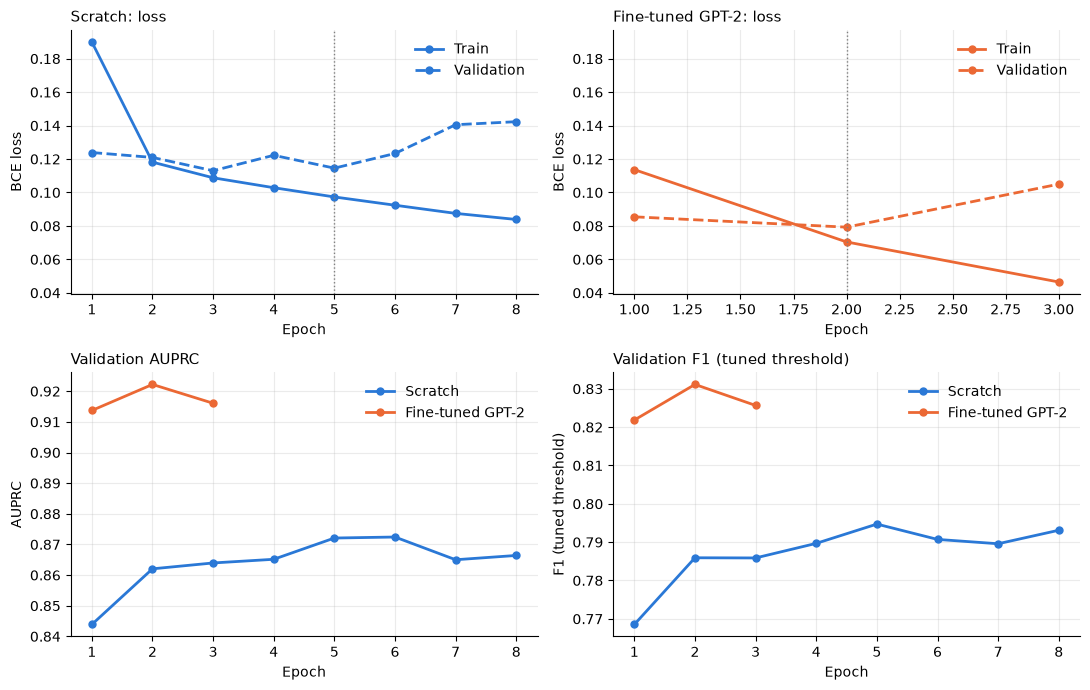

In [33]:
import matplotlib.pyplot as plt

COLOR_SC, COLOR_FT = "#2a78d6", "#eb6834"


def style_axis(ax, title, ylabel):
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)


fig, axes = plt.subplots(2, 2, figsize=(11, 7))
# Both loss panels share the y scale, so the train/validation gap is comparable.
axes[0, 1].sharey(axes[0, 0])

# Top row: train and validation loss for each model.
for ax, history, color, name in [
    (axes[0, 0], history_sc, COLOR_SC, "Scratch"),
    (axes[0, 1], history_ft, COLOR_FT, "Fine-tuned GPT-2"),
]:
    ax.plot(
        history["epoch"],
        history["train_loss"],
        color=color,
        lw=2,
        marker="o",
        ms=5,
        label="Train",
    )
    ax.plot(
        history["epoch"],
        history["val_loss"],
        color=color,
        lw=2,
        ls="--",
        marker="o",
        ms=5,
        label="Validation",
    )
    # Epoch whose weights were restored by early stopping.
    ax.axvline(history["best_epoch"], color="gray", lw=1, ls=":")
    style_axis(ax, f"{name}: loss", "BCE loss")
    ax.legend(frameon=False)

# Bottom row: validation quality of both models on the same axes.
for ax, key, title in [
    (axes[1, 0], "val_auprc", "Validation AUPRC"),
    (axes[1, 1], "val_f1_tuned", "Validation F1 (tuned threshold)"),
]:
    for history, color, name in [
        (history_sc, COLOR_SC, "Scratch"),
        (history_ft, COLOR_FT, "Fine-tuned GPT-2"),
    ]:
        ax.plot(
            history["epoch"],
            history[key],
            color=color,
            lw=2,
            marker="o",
            ms=5,
            label=name,
        )
    style_axis(ax, title, title.replace("Validation ", ""))
    ax.legend(frameon=False)

fig.tight_layout()
plt.show()

## Constrained decoding

In [34]:
from transformers import AutoModelForCausalLM


class GPTCausal(nn.Module):
    def __init__(self, name: str, tokenizer):
        super().__init__()
        self.model = AutoModelForCausalLM.from_pretrained(name)
        self.tokenizer = tokenizer
        self.model.config.pad_token_id = tokenizer.pad_token_id

        yes_ids = tokenizer.encode(" yes", add_special_tokens=False)
        no_ids = tokenizer.encode(" no", add_special_tokens=False)
        assert len(yes_ids) == 1 and len(no_ids) == 1, (
            "Label words must be single tokens"
        )

        # Order defines class index: 0 = no, 1 = yes
        self.register_buffer("label_ids", torch.tensor([no_ids[0], yes_ids[0]]))

    def forward_not_optimal(self, input_ids, attention_mask):
        out = self.model(input_ids=input_ids, attention_mask=attention_mask)
        logits = out.logits

        # Index of the last real token (right padding: mask is 1...1 0...0)
        last = (attention_mask.sum(dim=1) - 1).clamp(min=0)  # (B,)

        B = logits.size(0)
        next_token_logits = logits[
            torch.arange(B, device=logits.device), last
        ]  # (B, V)

        # Keep only the two label tokens: (B, 2) = [no, yes]
        return next_token_logits[:, self.label_ids]

    def forward(self, input_ids, attention_mask):
        # Score only the two label tokens (" no", " yes") at the last real token,
        # reusing the existing LM head rows instead of computing full-vocab logits.
        # Equivalent to full logits + column selection, but cheaper. No new parameters.

        # Backbone only: hidden states (B, T, D), no full-vocab projection.
        hidden = self.model.base_model(
            input_ids=input_ids, attention_mask=attention_mask
        ).last_hidden_state

        # Index of the last real token (right padding).
        last = (attention_mask.sum(dim=1) - 1).clamp(min=0)
        B = hidden.size(0)
        h = hidden[torch.arange(B, device=hidden.device), last]  # (B, D)

        # Project only onto the two label token rows of the output matrix.
        head = self.model.get_output_embeddings()  # lm_head (tied with wte in GPT-2)
        W = head.weight[self.label_ids]  # (2, D)
        bias = (
            head.bias[self.label_ids]
            if getattr(head, "bias", None) is not None
            else None
        )

        return F.linear(h, W, bias)  # (B, 2) = [no, yes]

In [35]:
model_cd = GPTCausal(GPT_MODEL_NAME, tokenizer_pt).to(device)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]